# ___Netflix product analysis:___

## importing librearies:

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## step_1 =>> loading data 

In [87]:
# importing and checking data
data=pd.read_csv('netflix_content.csv')
data.shape
data.columns
data.dtypes
data.head(10)

,Title,Available Globally?,Release Date,Hours Viewed,Language Indicator,Content Type
0,The Night Agent: Season 1,Yes,2023-03-23,"81,21,00,000",English,Show
1,Ginny & Georgia: Season 2,Yes,2023-01-05,"66,51,00,000",English,Show
2,The Glory: Season 1 // 더 글로리: 시즌 1,Yes,2022-12-30,"62,28,00,000",Korean,Show
3,Wednesday: Season 1,Yes,2022-11-23,"50,77,00,000",English,Show
4,Queen Charlotte: A Bridgerton Story,Yes,2023-05-04,"50,30,00,000",English,Movie
5,You: Season 4,Yes,2023-02-09,"44,06,00,000",English,Show
6,La Reina del Sur: Season 3,No,2022-12-30,"42,96,00,000",English,Show
7,Outer Banks: Season 3,Yes,2023-02-23,"40,25,00,000",English,Show
8,Ginny & Georgia: Season 1,Yes,2021-02-24,"30,21,00,000",English,Show
9,FUBAR: Season 1,Yes,2023-05-25,"26,62,00,000",English,Show


## step_2 =>> ___data pri_processing:-___

In [88]:
#check null 
data.isnull().sum()
#check duplicate row
data[data.duplicated()]
#removing duplicate row
data.drop_duplicates(inplace=True)
data.duplicated().sum()


np.int64(0)

In [89]:
# convert data types
data['Available Globally?']=data['Available Globally?'].map({'Yes':True,'No':False})
data['Release Date']=pd.to_datetime(data['Release Date'])
data['Hours Viewed']=data['Hours Viewed'].str.replace(',','',regex=False).astype('int64')
data.dtypes


Title                             str
Available Globally?              bool
Release Date           datetime64[us]
Hours Viewed                    int64
Language Indicator                str
Content Type                      str
dtype: object

In [90]:
# seperating date columns:
data['Release year']=data['Release Date'].dt.year
data['Release months']=data['Release Date'].dt.month
data['Release day name']=data['Release Date'].dt.day_name()

## step_3 =>> ___data analysis with pandas.___

In [91]:
data.head(5)

,Title,Available Globally?,Release Date,Hours Viewed,Language Indicator,Content Type,Release year,Release months,Release day name
0,The Night Agent: Season 1,True,2023-03-23,812100000,English,Show,2023.0,3.0,Thursday
1,Ginny & Georgia: Season 2,True,2023-01-05,665100000,English,Show,2023.0,1.0,Thursday
2,The Glory: Season 1 // 더 글로리: 시즌 1,True,2022-12-30,622800000,Korean,Show,2022.0,12.0,Friday
3,Wednesday: Season 1,True,2022-11-23,507700000,English,Show,2022.0,11.0,Wednesday
4,Queen Charlotte: A Bridgerton Story,True,2023-05-04,503000000,English,Movie,2023.0,5.0,Thursday


### Q1 which 10 title have highest viewing hours...?

In [92]:
# 10 titlw have highest viewed hours:-
top10=data.nlargest(10,'Hours Viewed')
print(top10[['Title','Hours Viewed']])

                                                 Title  Hours Viewed
0                            The Night Agent: Season 1     812100000
1                            Ginny & Georgia: Season 2     665100000
18227  King the Land: Limited Series // 킹더랜드: 리미티드 시리즈     630200000
2                   The Glory: Season 1 // 더 글로리: 시즌 1     622800000
18214                              ONE PIECE: Season 1     541900000
3                                  Wednesday: Season 1     507700000
4                  Queen Charlotte: A Bridgerton Story     503000000
5                                        You: Season 4     440600000
6                           La Reina del Sur: Season 3     429600000
7                                Outer Banks: Season 3     402500000


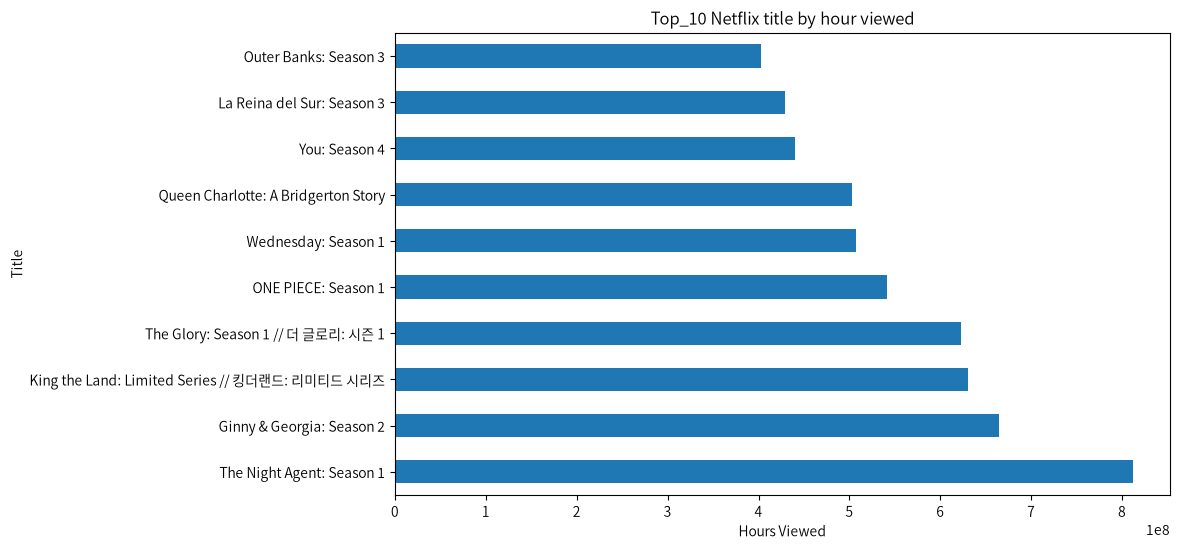

In [93]:
top10.plot(x='Title',y='Hours Viewed',kind='barh',figsize=(10,6),legend=False)
plt.title('Top_10 Netflix title by hour viewed')
plt.xlabel('Hours Viewed')
plt.ylabel('Title')
plt.show()

## Q2 total viewing hours by Content type

In [ ]:
# total viewing hours by Content type
total_hour=data.groupby('Content Type')['Hours Viewed'].sum() 
print(total_hour)                  

Content Type
Movie     50543800000
Show     107426900000
Name: Hours Viewed, dtype: int64


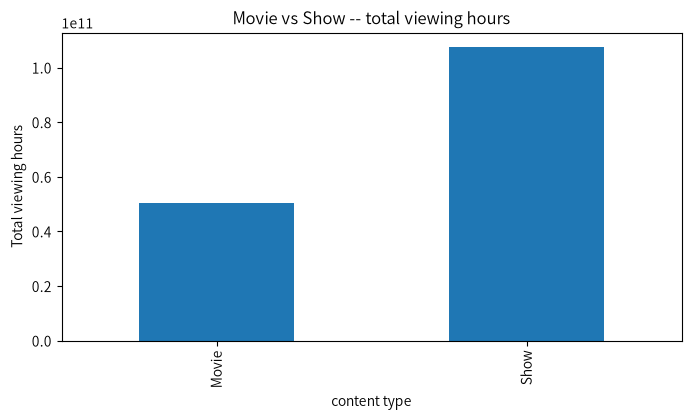

In [95]:
total_hour.plot(kind='bar',figsize=(8,4),legend=False)
plt.title('Movie vs Show -- total viewing hours')
plt.xlabel('content type')
plt.ylabel('Total viewing hours')
plt.show()

## Average viewing hours par title (by Content type)

In [ ]:
# average viewing hours par title by Content type
avg_hour=data.groupby('Content Type')['Hours Viewed'].mean().round()
print(avg_hour)                  

Content Type
Movie     3634153.0
Show     10292891.0
Name: Hours Viewed, dtype: float64


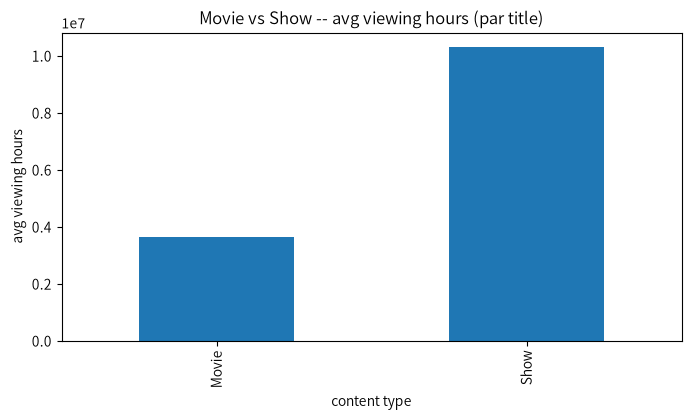

In [97]:
avg_hour.plot(kind='bar',figsize=(8,4),legend=False)
plt.title('Movie vs Show -- avg viewing hours (par title)')
plt.xlabel('content type')
plt.ylabel('avg viewing hours')
plt.show()

## % of total viewing hours from top 10 title

In [ ]:
# % of total viewing hours from top 10 title
top10_watching_hour=data.nlargest(10,'Hours Viewed')['Hours Viewed'].sum()
top10_watching_persent=top10_watching_hour*100/data['Hours Viewed'].sum()
top10_watching_persent.round(2)                                  

np.float64(3.52)

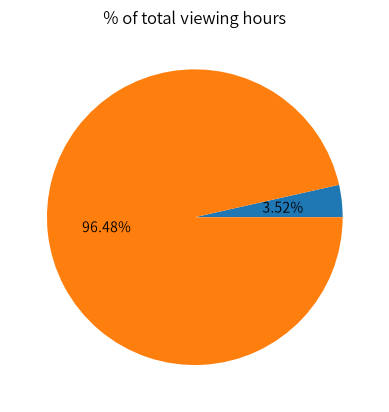

In [99]:
# calculating other watching hour
other_watching_hour=data['Hours Viewed'].sum()-top10_watching_hour

# making pie chart 
plt.pie([top10_watching_hour,other_watching_hour],
        autopct='%1.2f%%',)
plt.title('% of total viewing hours')
plt.show()


## Do Available Globally? get more watching hour or not?

In [ ]:
# globally available vs unavailable
global_avg=data.groupby('Available Globally?')['Hours Viewed'].mean().round()  
print(global_avg)                                                

Available Globally?
False     4319822.0
True     11388715.0
Name: Hours Viewed, dtype: float64


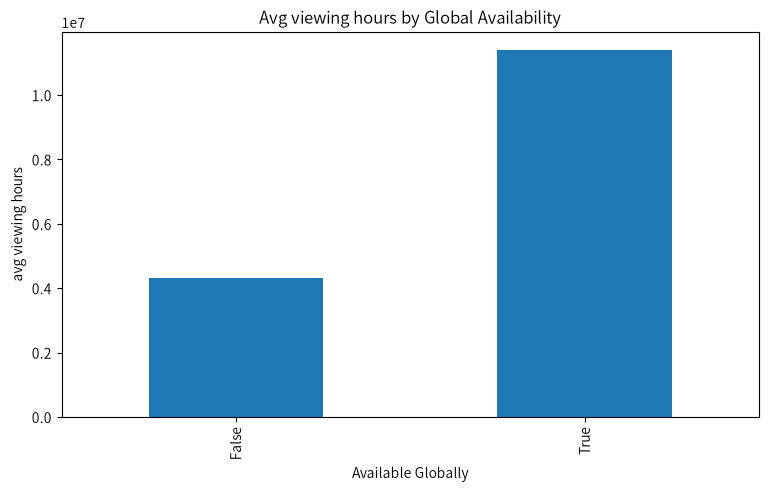

In [101]:
global_avg.plot(kind='bar',figsize=(9,5),legend=False)
plt.title('Avg viewing hours by Global Availability')
plt.xlabel('Available Globally')
plt.ylabel('avg viewing hours')
plt.show()

## top Languages by total viewing hours

In [ ]:
# total viewing hour by language
Language_hour=data.groupby('Language Indicator')['Hours Viewed'].sum().nlargest(5)
print(Language_hour)                                                             

Language Indicator
English        124092000000
Korean          15371100000
Non-English     10414700000
Japanese         7063300000
Hindi             915000000
Name: Hours Viewed, dtype: int64


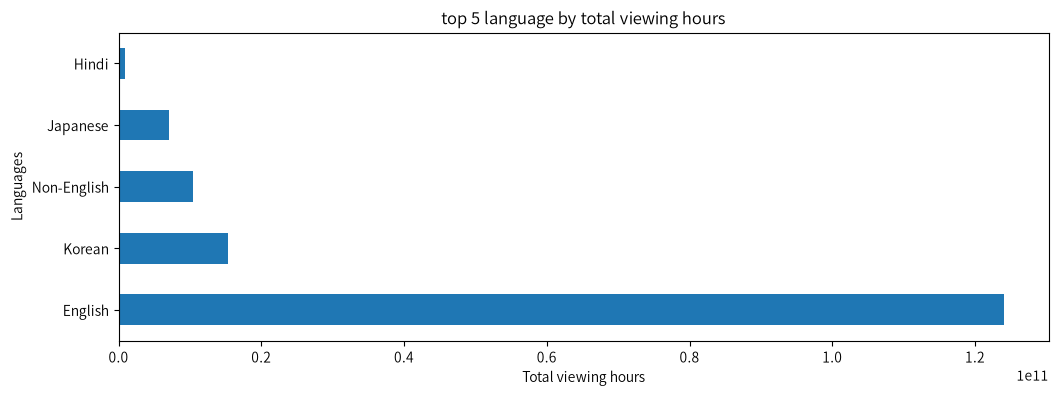

In [103]:
Language_hour.plot(kind='barh',figsize=(12,4),legend=False)
plt.title('top 5 language by total viewing hours')
plt.xlabel('Total viewing hours')
plt.ylabel('Languages')
plt.show()

## performance diffrance btw english and non english title 

In [ ]:
# viewing performance diffrance btw english and non english title 
data['language type']=data['Language Indicator'].apply(lambda x:'English' if x=='English' else 'Non_english')
Language_total_hour=data.groupby('language type')['Hours Viewed'].mean()
diffrance=Language_total_hour['English']-Language_total_hour['Non_english']              
print(diffrance)                                                                 


2748171.5202767337


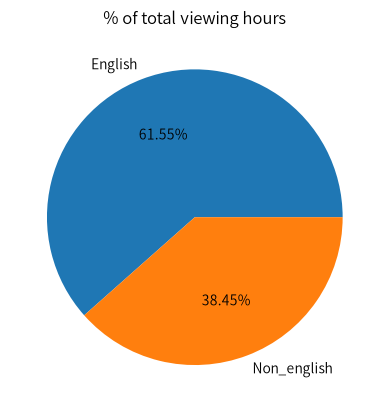

In [ ]:
# prtformance of english & non-english 
Language_total_hour.plot(kind='pie',
        autopct='%1.2f%%')
plt.title('% of total viewing hours')
plt.show()

## realtion between relesed date and watching hour 

In [ ]:
# realtion between relesed date and watching hour 
data['Release Date'].corr(data['Hours Viewed'])                    ;
data['Release year'].corr(data['Hours Viewed'])                    


np.float64(0.1971749536976897)

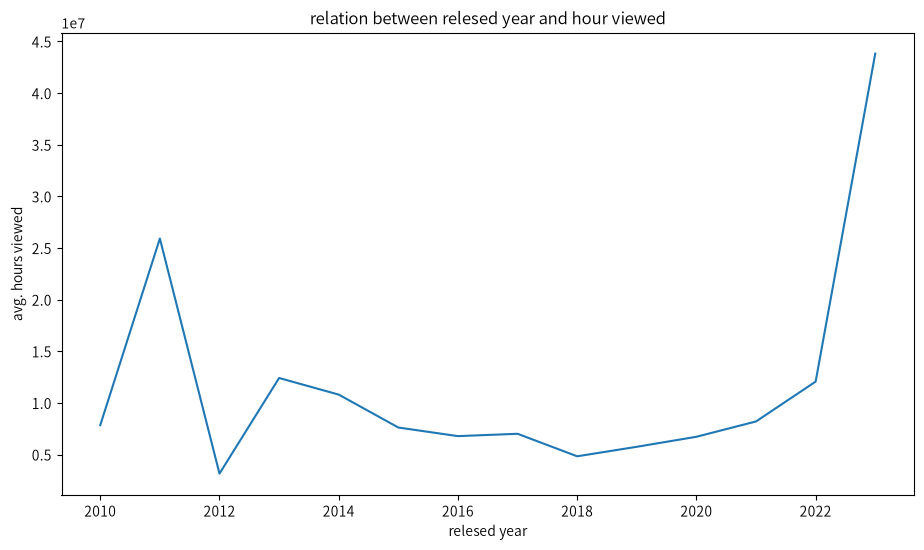

In [107]:
year_avg=data.groupby('Release year')['Hours Viewed'].mean()
year_avg.plot(kind='line',figsize=(11,6))
plt.title("relation between relesed year and hour viewed")
plt.xlabel('relesed year')
plt.ylabel("avg. hours viewed")
plt.show()

## Released year vs title count

In [117]:
title_par_year=data.groupby('Release year')['Title'].count()
print(title_par_year)

Release year
2010.0      16
2011.0       6
2012.0       2
2013.0      21
2014.0      47
2015.0     142
2016.0     325
2017.0     569
2018.0     947
2019.0    1109
2020.0    1218
2021.0    1255
2022.0    1532
2023.0     786
Name: Title, dtype: int64


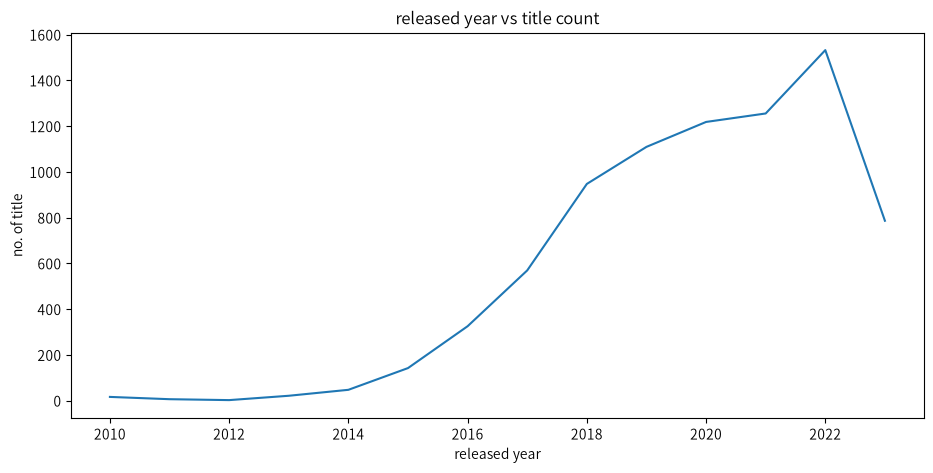

In [120]:
title_par_year.plot(kind='line',figsize=(11,5))
plt.title(' released year vs title count ')
plt.xlabel('released year')
plt.ylabel('no. of title')
plt.show()

## watching hour trand by week days

In [108]:
# checking day of week wise avg viewed hours
week_day_hour=data.groupby('Release day name')['Hours Viewed'].mean().round() 
week_day_hour

Release day name
Friday       10064714.0
Monday        9274178.0
Saturday     22162338.0
Sunday       11116092.0
Thursday     17984117.0
Tuesday       5863983.0
Wednesday    12246417.0
Name: Hours Viewed, dtype: float64

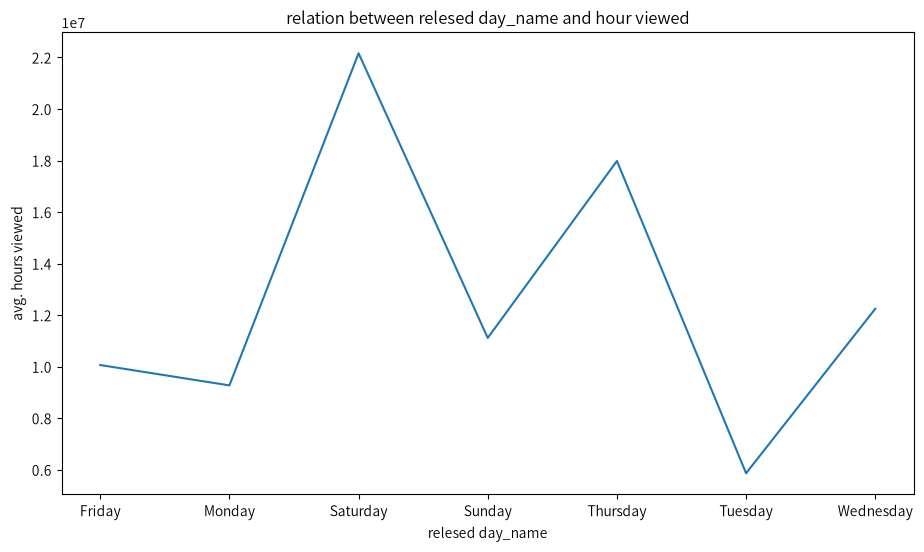

In [109]:
week_day_hour.plot(kind='line',figsize=(11,6))
plt.title("relation between relesed day_name and hour viewed")
plt.xlabel('relesed day_name')
plt.ylabel("avg. hours viewed")
plt.show()

##  No. of title with relesed missing date & present date

In [110]:
# total missing date vs total present date
total_date_missing =data['Release Date'].isnull().sum()
total_date_present=data['Release Date'].notnull().sum()
print(total_date_missing,total_date_present)

16370 7975


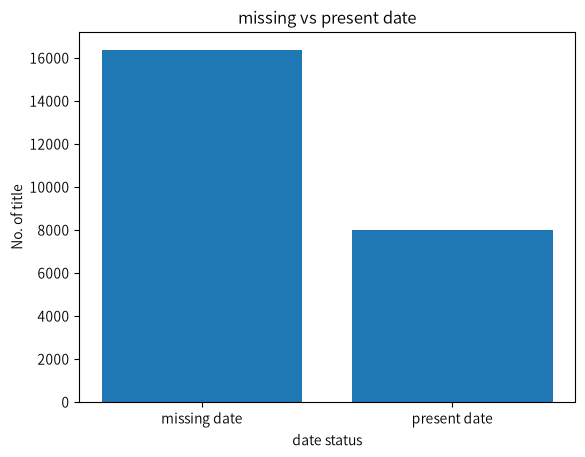

In [111]:
plt.bar(['missing date','present date'],[total_date_missing,total_date_present])
plt.title("missing vs present date")
plt.xlabel("date status")
plt.ylabel("No. of title")
plt.show()

## further investment reserch category

In [112]:
data.groupby('Content Type')['Hours Viewed'].agg(['sum','mean'])

,sum,mean
Content Type,,
Movie,50543800000,3.634153e+06
Show,107426900000,1.029289e+07


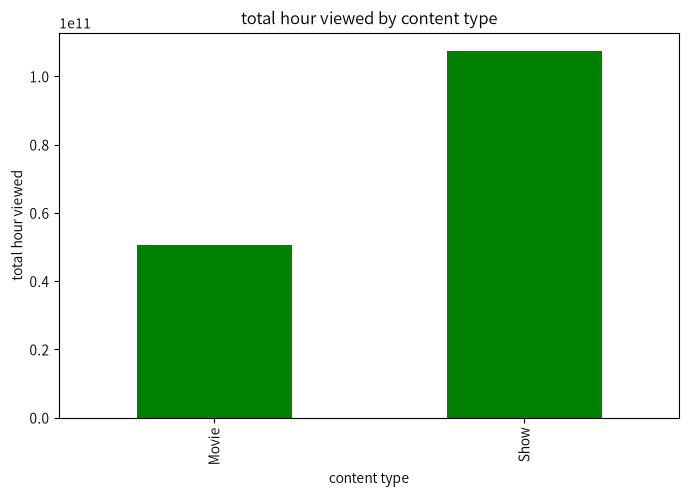

In [113]:
total__hour=data.groupby('Content Type')['Hours Viewed'].sum()
total__hour.plot(kind='bar',figsize=(8,5),color='green')
plt.title('total hour viewed by content type')
plt.xlabel('content type')
plt.ylabel('total hour viewed')
plt.show()

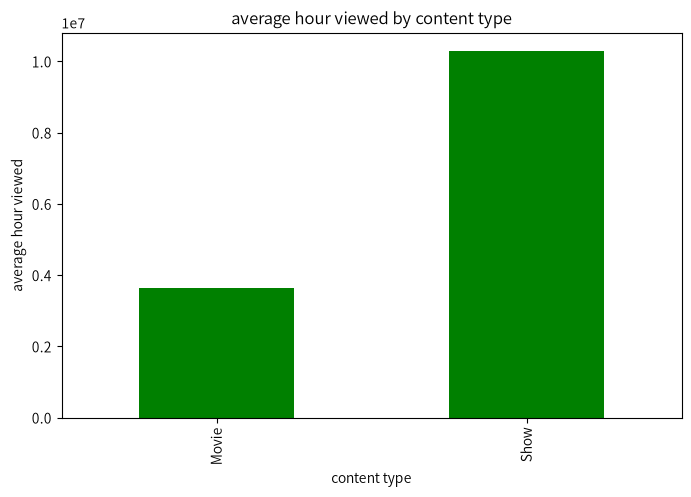

In [114]:
avg__hour=data.groupby('Content Type')['Hours Viewed'].mean()
avg__hour.plot(kind='bar',figsize=(8,5),color='green')
plt.title('average hour viewed by content type')
plt.xlabel('content type')
plt.ylabel('average hour viewed')
plt.show()

## ____viewing hour distribution____ :

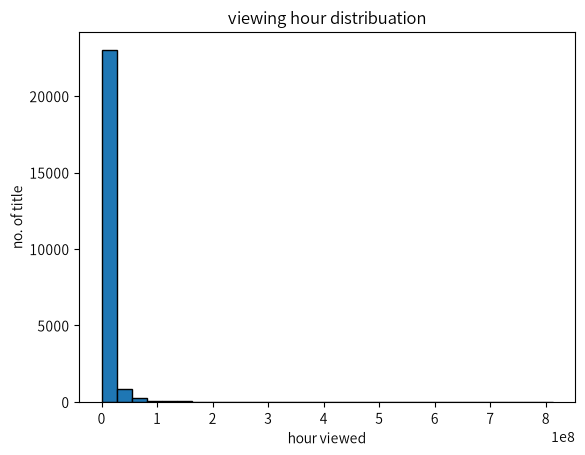

In [132]:

plt.hist(data['Hours Viewed'],bins=30,edgecolor='black')
plt.title('viewing hour distribuation')
plt.xlabel('hour viewed')
plt.ylabel('no. of title')
plt.show()